In [ ]:
#Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path
import seaborn as sns
import warnings
import os

from sqlalchemy import create_engine

In [4]:
# Настройка путей
SRC_DIR = Path.cwd()
DATA_RAW = os.path.join(SRC_DIR, 'data')

# Создание папок
os.makedirs(DATA_RAW, exist_ok=True)

In [5]:
# Загрузка данных
data_path = os.path.join(DATA_RAW, 'Pharma_data_analysis.xlsx')

if not os.path.exists(data_path):
    raise FileNotFoundError(f"Файл не найден: {data_path}")

df = pd.read_excel(data_path)

print(f"Данные: {len(df)} строк")

Данные: 254082 строк


In [5]:
df.head()

,Distributor,Customer Name,City,Country,Latitude,Longitude,Channel,Sub-channel,Product Name,Product Class,Quantity,Price,Sales,Month,Year,Name of Sales Rep,Manager,Sales Team
0,Gottlieb-Cruickshank,"Zieme, Doyle and Kunze",Lublin,Poland,51.2333,22.5667,Hospital,Private,Topipizole,Mood Stabilizers,4.0,368,1472.0,January,2018,Mary Gerrard,Britanny Bold,Delta
1,Gottlieb-Cruickshank,Feest PLC,Åšwiecie,Poland,53.4167,18.4333,Pharmacy,Retail,Choriotrisin,Antibiotics,7.0,591,4137.0,January,2018,Jessica Smith,Britanny Bold,Delta
2,Gottlieb-Cruickshank,Medhurst-Beer Pharmaceutical Limited,Rybnik,Poland,50.0833,18.5000,Pharmacy,Institution,Acantaine,Antibiotics,30.0,66,1980.0,January,2018,Steve Pepple,Tracy Banks,Bravo
3,Gottlieb-Cruickshank,Barton Ltd Pharma Plc,CzeladÅº,Poland,50.3333,19.0833,Hospital,Private,Lioletine Refliruvax,Analgesics,6.0,435,2610.0,January,2018,Mary Gerrard,Britanny Bold,Delta
4,Gottlieb-Cruickshank,Keeling LLC Pharmacy,Olsztyn,Poland,53.7800,20.4942,Pharmacy,Retail,Oxymotroban Fexoformin,Analgesics,20.0,458,9160.0,January,2018,Anne Wu,Britanny Bold,Delta


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 254082 entries, 0 to 254081
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Distributor        254082 non-null  str    
 1   Customer Name      254082 non-null  str    
 2   City               254082 non-null  str    
 3   Country            254082 non-null  str    
 4   Latitude           254082 non-null  float64
 5   Longitude          254082 non-null  float64
 6   Channel            254082 non-null  str    
 7   Sub-channel        254082 non-null  str    
 8   Product Name       254082 non-null  str    
 9   Product Class      254082 non-null  str    
 10  Quantity           254082 non-null  float64
 11  Price              254082 non-null  int64  
 12  Sales              254082 non-null  float64
 13  Month              254082 non-null  str    
 14  Year               254082 non-null  int64  
 15  Name of Sales Rep  254082 non-null  str    
 16  Manager      

In [47]:
df.isnull().sum()

Distributor          0
Customer Name        0
City                 0
Country              0
Latitude             0
Longitude            0
Channel              0
Sub-channel          0
Product Name         0
Product Class        0
Quantity             0
Price                0
Sales                0
Month                0
Year                 0
Name of Sales Rep    0
Manager              0
Sales Team           0
dtype: int64

In [48]:
df.describe()

,Latitude,Longitude,Quantity,Price,Sales,Year
count,254082.000000,254082.000000,254082.000000,254082.000000,2.540820e+05,254082.000000
mean,50.962222,10.803212,112.872139,412.207720,4.643772e+04,2018.385187
std,1.625526,4.143311,744.310385,224.963687,3.491918e+05,1.041352
min,47.514200,6.083800,-7200.000000,22.000000,-4.161600e+06,2017.000000
25%,49.805600,7.891100,5.000000,195.000000,1.704000e+03,2018.000000
50%,51.133300,9.397800,20.000000,430.000000,5.850000e+03,2018.000000
75%,52.083300,12.133300,50.000000,605.000000,2.156525e+04,2019.000000
max,54.781900,23.566700,117600.000000,794.000000,7.420560e+07,2020.000000


In [6]:
df['Date'] = pd.to_datetime((df['Month']+ '' + df['Year'].astype('str')), format='%B%Y')

In [7]:
df.duplicated().sum()
df.drop_duplicates()

,Distributor,Customer Name,City,Country,Latitude,Longitude,Channel,Sub-channel,Product Name,Product Class,Quantity,Price,Sales,Month,Year,Name of Sales Rep,Manager,Sales Team,Date
0,Gottlieb-Cruickshank,"Zieme, Doyle and Kunze",Lublin,Poland,51.2333,22.5667,Hospital,Private,Topipizole,Mood Stabilizers,4.0,368,1472.0,January,2018,Mary Gerrard,Britanny Bold,Delta,2018-01-01
1,Gottlieb-Cruickshank,Feest PLC,Åšwiecie,Poland,53.4167,18.4333,Pharmacy,Retail,Choriotrisin,Antibiotics,7.0,591,4137.0,January,2018,Jessica Smith,Britanny Bold,Delta,2018-01-01
2,Gottlieb-Cruickshank,Medhurst-Beer Pharmaceutical Limited,Rybnik,Poland,50.0833,18.5000,Pharmacy,Institution,Acantaine,Antibiotics,30.0,66,1980.0,January,2018,Steve Pepple,Tracy Banks,Bravo,2018-01-01
3,Gottlieb-Cruickshank,Barton Ltd Pharma Plc,CzeladÅº,Poland,50.3333,19.0833,Hospital,Private,Lioletine Refliruvax,Analgesics,6.0,435,2610.0,January,2018,Mary Gerrard,Britanny Bold,Delta,2018-01-01
4,Gottlieb-Cruickshank,Keeling LLC Pharmacy,Olsztyn,Poland,53.7800,20.4942,Pharmacy,Retail,Oxymotroban Fexoformin,Analgesics,20.0,458,9160.0,January,2018,Anne Wu,Britanny Bold,Delta,2018-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
254077,Bashirian-Kassulke,"Koch, Borer and Hagenes Pharmaceutical Ltd",Lauf,Germany,49.5103,11.2772,Hospital,Private,Pentastrin,Antibiotics,919.0,497,456743.0,December,2020,Thompson Crawford,James Goodwill,Alfa,2020-12-01
254078,Bashirian-Kassulke,Hane Ltd Pharmaceutical Ltd,Aichach,Germany,48.4500,11.1333,Hospital,Private,Abranatal Lysoprosate,Antiseptics,432.0,681,294192.0,December,2020,Anne Wu,Britanny Bold,Delta,2020-12-01
254079,Bashirian-Kassulke,Harris-Conroy Pharmacy,Wilhelmshaven,Germany,53.5167,8.1333,Pharmacy,Retail,Adideine,Mood Stabilizers,320.0,678,216960.0,December,2020,Abigail Thompson,Tracy Banks,Bravo,2020-12-01
254080,Bashirian-Kassulke,Balistreri Group Pharm,BÃ¶blingen,Germany,48.6833,9.0000,Hospital,Government,Feruprazole,Mood Stabilizers,565.0,115,64975.0,December,2020,Stella Given,Alisha Cordwell,Charlie,2020-12-01


1. Загрузка данных в SQL

In [21]:
username = "postgres"
password = "admin"
host = "localhost"
port = "5433"
database = "Pharma_sales"

engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

table_name = "sales_data"
df.to_sql(
    name=table_name,
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=1000
)

print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")

Data successfully loaded into table 'sales_data' in database 'Pharma_sales'.


2. EDA
Разведочный анализ данных (EDA) исследует тенденции продаж, наиболее успешные страны и продукты, а также сезонные и региональные закономерности в данных. Для подтверждения выводов использовались визуализации и описательные статистики.

In [56]:
# Общая выручка
Total_sales = df['Sales'].sum()
print(f"Общая выручка: ${Total_sales:,.2f}")

Общая выручка: $11,798,987,642.20


In [58]:
# Продукты с наибольшей и наименьшей выручкой
product_sales = df.groupby('Product Name')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False)

highest_sales_product = product_sales.iloc[0]['Product Name']
highest_sale = product_sales.iloc[0]['Sales']
print(f"Продукт с наибольшей выручкой: {highest_sales_product} (${highest_sale:,.2f})")

lowest_sales_product = product_sales.iloc[-1]['Product Name']
lowest_sale = product_sales.iloc[-1]['Sales']
print(f"Продукт с наименьшей выручкой: {lowest_sales_product} (${lowest_sale:,.2f})")

Продукт с наибольшей выручкой: Ionclotide ($169,083,391.00)
Продукт с наименьшей выручкой: Amphesirox ($2,623,450.00)


In [59]:
# Продукты с наибольшим и наименьшим количеством продаж
product_quantity = df.groupby('Product Name')['Quantity'].sum().reset_index().sort_values(by = 'Quantity', ascending=False)

highest_quantity_product = product_quantity.iloc[0]['Product Name']
highest_quantity = product_quantity.iloc[0]['Quantity']
print(f"Продукты с наибольшим количеством продаж: {highest_quantity_product} (${highest_quantity:,.2f})")

lowest_quantity_product = product_quantity.iloc[-1]['Product Name']
lowest_quantity = product_quantity.iloc[-1]['Quantity']
print(f"Продукты с наименьшим количеством продаж: {lowest_quantity_product} (${lowest_quantity:,.2f})")

Продукты с наибольшим количеством продаж: Ionclotide ($267,961.00)
Продукты с наименьшим количеством продаж: Diaxolol ($77,178.00)


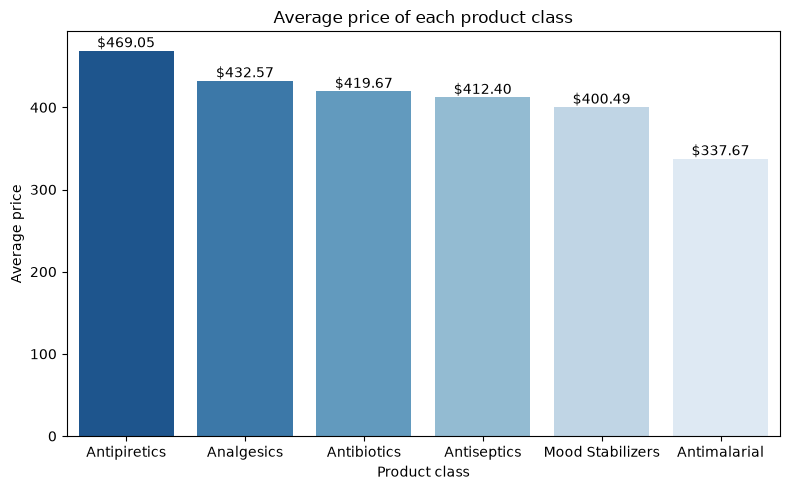

In [62]:
# Средняя цена по категориям продукта (Product Class)
product_class_price = df.groupby('Product Class', as_index=False)['Price'].mean().sort_values(by='Price', ascending=False)

plt.figure(figsize = (8,5))
ax = sns.barplot(data = product_class_price, x='Product Class', y='Price', hue='Product Class', palette='Blues_r')

for i in ax.patches:
    ax.annotate(f'${i.get_height():,.2f}',
               (i.get_x() + i.get_width() / 2, i.get_height()), ha='center', va='bottom')
                
plt.xlabel('Product class')
plt.ylabel('Average price')
plt.title('Average price of each product class')
plt.tight_layout()
plt.show()

Средняя цена была рассчитана для каждого класса продуктов, чтобы понять ценовые тенденции по категориям. Наибольшая средняя цена — у антипиретиков, за ними следуют анальгетики и антибиотики.На нижнем конце диапазона наименьшая средняя цена зафиксирована у противомалярийных, а нормотимики и антисептики заняли второе и третье место с конца соответственно. Этот анализ даёт наглядное представление о ценовой стратегии и возможном восприятии ценности в различных терапевтических сегментах.

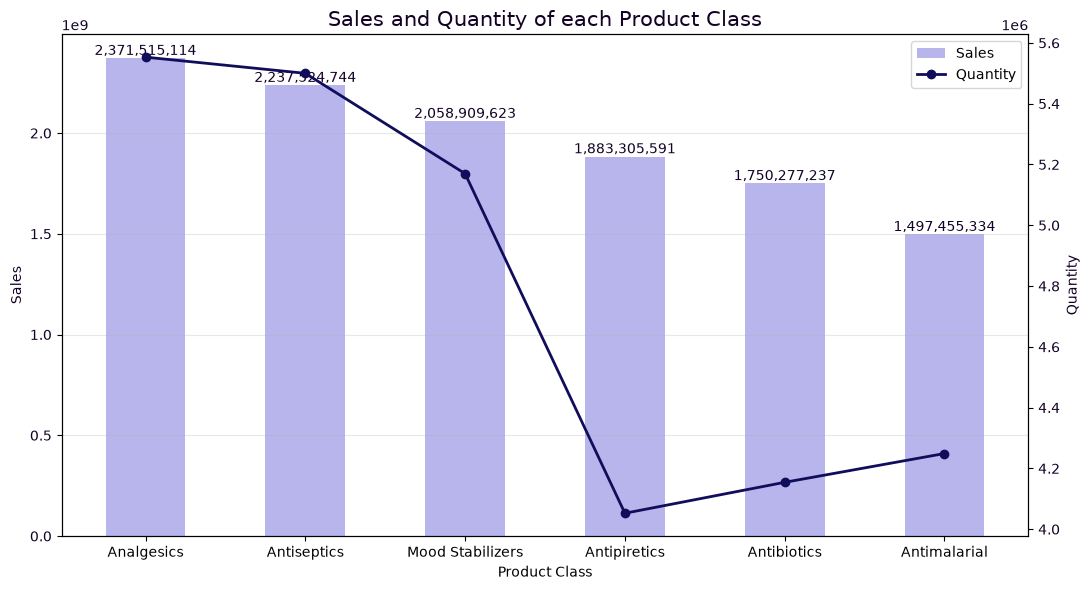

In [64]:
product_sales_quantity = (
    df.groupby('Product Class', as_index=False)[['Sales','Quantity']]
      .sum()
      .sort_values('Sales', ascending=False)
      .reset_index(drop=True)
)

fig, ax1 = plt.subplots(figsize=(11, 6))

# --- Sales: столбики, левая ось ---
bars = ax1.bar(product_sales_quantity['Product Class'],
               product_sales_quantity['Sales'],
               width=0.5,color="#A6A3E8", alpha=0.8, label='Sales')
ax1.set_xlabel('Product Class')
ax1.set_ylabel('Sales', color='#130225')
ax1.tick_params(axis='y', labelcolor="#130225")

for b, v in zip(bars, product_sales_quantity['Sales']):
    ax1.text(b.get_x() + b.get_width()/2, v, f'{v:,.0f}',
             ha='center', va='bottom', fontsize=10, color="#130225")

# --- Quantity: линия, правая ось ---
ax2 = ax1.twinx()
ax2.plot(product_sales_quantity['Product Class'],
         product_sales_quantity['Quantity'],
         color="#100E5A", marker='o', linewidth=2, label='Quantity')
ax2.set_ylabel('Quantity', color='#130225')
ax2.tick_params(axis='y', labelcolor='#130225')

ax1.grid(True, axis='y', alpha=0.3)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right')

plt.title('Sales and Quantity of each Product Class',color = '#130225', fontsize=15)
plt.tight_layout()
plt.show()

Наибольшая выручка и количество продаж у категории анальгетики, за ними - антипиретики и нормотимики. В общем, наблюдается взаимосвязь количества продаж и выручки, за исключением одной категории (антипиретики). У данной категории относительно небольшое количество продаж и высокая выручка, что говорит о высокой цене.

3. Аналитика географии
Данные по продажам были рассмотрены в разрезе стран и городов, чтобы определить, какие регионы внесли наибольший вклад в общий доход. Этот анализ помогает выявить рынки с высокой производительностью.

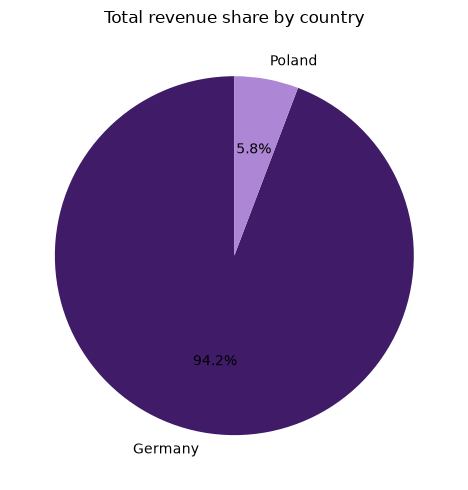

In [ ]:
# Доля выручки по странам
revenue_country = df.groupby('Country')['Sales'].sum().reset_index()

plt.figure(figsize = (7,5))
ax = plt.pie(x = revenue_country['Sales'], labels=revenue_country['Country'], autopct='%1.1f%%', startangle=90, colors=["#3F1B68", "#AD86D6"])
                
plt.title('Total revenue share by country')
plt.tight_layout()
plt.show()

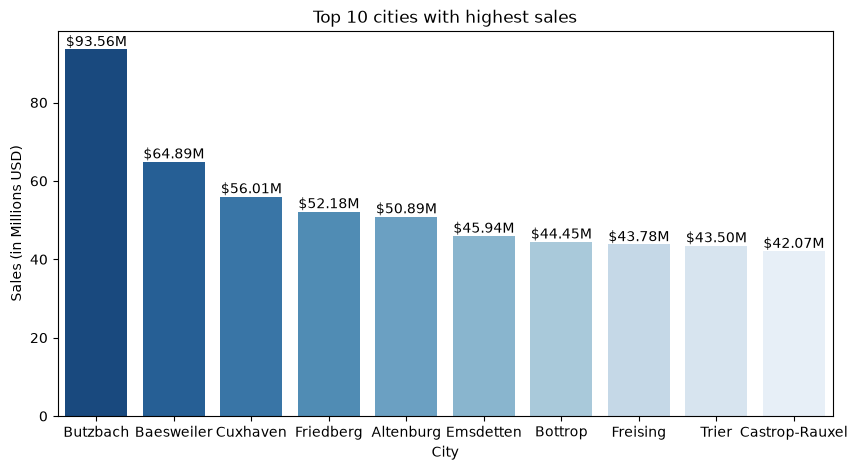

In [ ]:
# Топ 10 городов с наибольшим объемом продаж
revenue_cities = df.groupby('City')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False).head(10)

plt.figure(figsize = (10,5))
ax = sns.barplot(data = revenue_cities, x='City', y='Sales', palette='Blues_r', hue='City')

for i in ax.patches:
    ax.annotate(f'${i.get_height() / 1_000_000:,.2f}M',
               (i.get_x() + i.get_width() / 2, i.get_height()), ha='center', va='bottom')
    
def millions(x, pos):
    return f'{int(x/1_000_000):,}'
ax.yaxis.set_major_formatter(FuncFormatter(millions))
                
plt.xlabel('City')
plt.ylabel('Sales (in Millions USD)')
plt.title('Top 10 cities with highest sales')
plt.show()

Анализ продаж по городам показал, что Butzbach зафиксировал наибольший общий объём продаж. Следующими по результативности городами стали:
- Baesweiler
- Cuxhaven
- Friedberg
- Atenburg
В первую десятку также вошли Emsdetten, Bottrop, Trier, Freising, Castrop-Rauxel. В совокупности эти города представляют собой регионы с высоким спросом и вносят значительный вклад в общие показатели бизнеса.

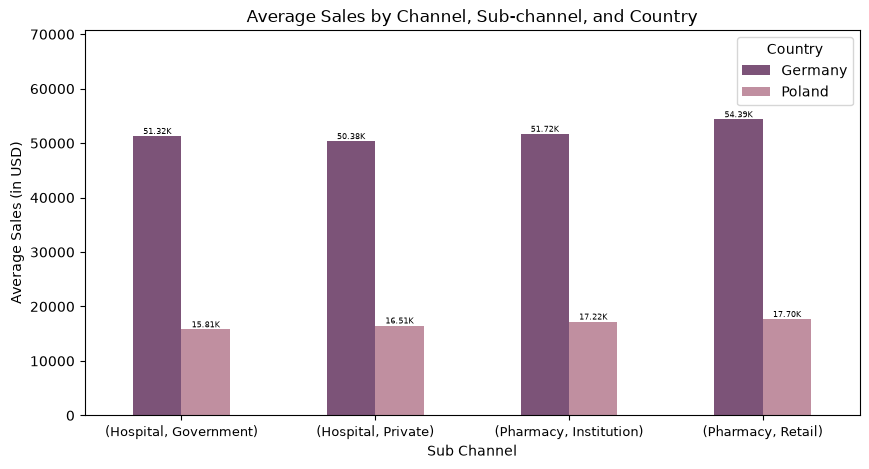

In [ ]:
# Каналы сбыта, показывающие наилучшие результаты в отдельных странах или городах
revenue_channel_country = df.groupby(['Channel','Sub-channel','Country'])['Sales'].mean().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
gc = revenue_channel_country.plot(kind='bar', stacked=False, ax=ax, color=['#7C5378', '#C08FA0'])

for i in gc.patches:
    gc.annotate(f'{i.get_height()/1000:,.2f}K', 
               (i.get_x() + i.get_width()/2, i.get_height()), ha='center', va='bottom', fontsize=6)


ymax = revenue_channel_country.max().max()
plt.ylim(0, ymax * 1.3)

plt.title('Average Sales by Channel, Sub-channel, and Country')
plt.xlabel('Sub Channel')
plt.xticks(rotation=0, fontsize=9)
plt.ylabel('Average Sales (in USD)')
plt.show()

Данные о продажах были проанализированы по различным каналам и подканалам сбыта, чтобы определить их влияние. Анализ показал минимальные различия в средних продажах между этими сегментами, что говорит о том, что тип сбыта существенно не влияет на объём продаж.

Тем не менее, сочетание «Pharmacy» как канал и «Retail» как подканал оказалось наиболее стабильным и результативным дуэтом, опережая остальные как по охвату, так и по выручке.

4. Временные тренды

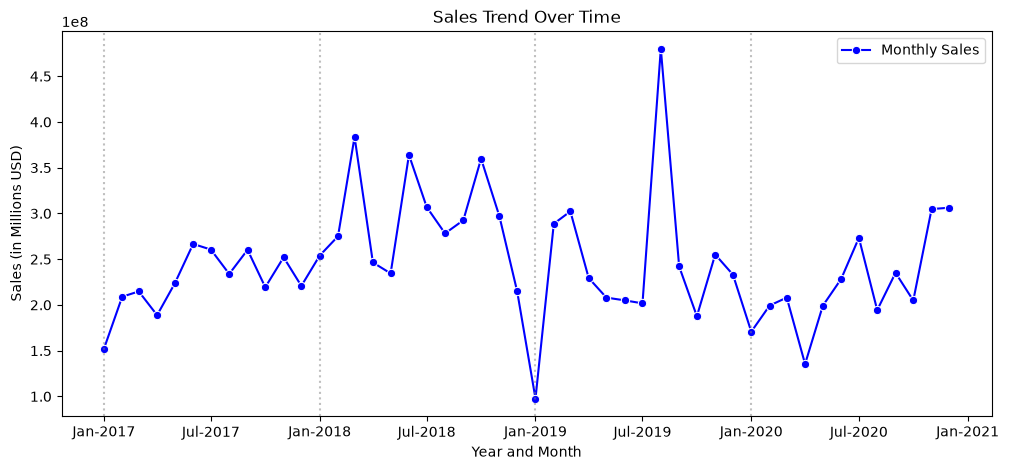

In [ ]:
# Тренд продаж по месяцам и годам
sales_date = df.groupby('Date')['Sales'].sum().reset_index()


plt.figure(figsize=(12, 5))
sns.lineplot(data=sales_date, x='Date', y='Sales', label='Monthly Sales', marker='o', color='Blue')

for year in sales_date['Date'].dt.year.unique():
    plt.axvline(pd.to_datetime(f'Jan-{year}'), color='gray', linestyle=':', alpha=0.5)

plt.xlabel('Year and Month')
plt.ylabel('Sales (in Millions USD)')
plt.title('Sales Trend Over Time')

plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b-%Y'))
plt.gca().yaxis.set_major_formatter(FuncFormatter(millions)) 
plt.show()

Анализ месячных и годовых тенденций продаж показал, что самые низкие продажи были зафиксированы в январе 2019 года, а пик продаж за год пришёлся на август 2019 года.

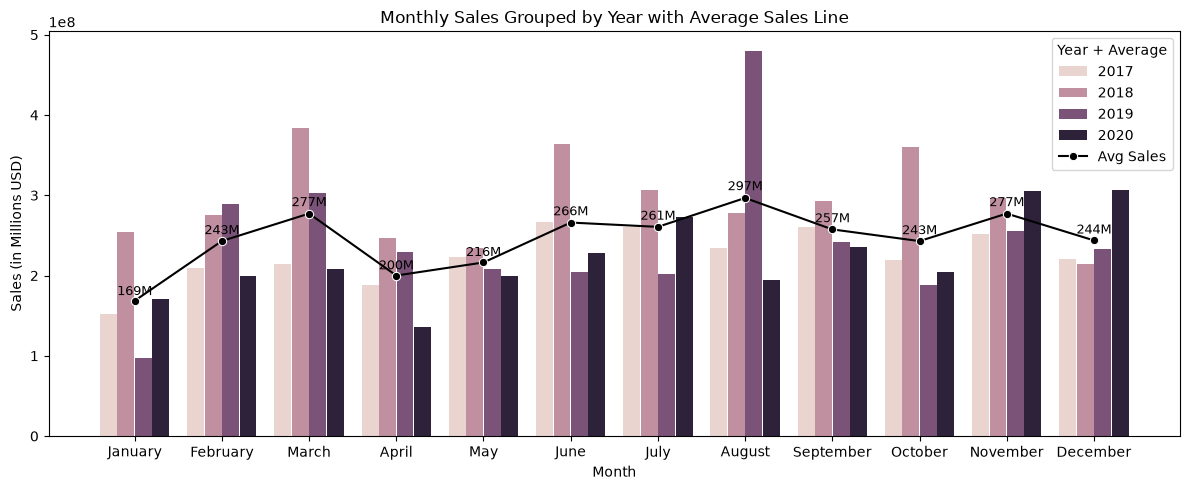

In [ ]:
#Месяцы с постоянно высокими продажами
monthly_sales = df.groupby(['Month', 'Year'])['Sales'].sum().reset_index()

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_sales['Month'] = pd.Categorical(monthly_sales['Month'], categories=month_order, ordered=True)

monthly_avg = monthly_sales.groupby('Month', observed=False)['Sales'].mean().reindex(month_order).reset_index()

plt.figure(figsize=(12, 5))
ax = sns.barplot(data=monthly_sales, x='Month', y='Sales', hue='Year', gap=0.03)
sns.lineplot(data=monthly_avg, x='Month', y='Sales', color='black', marker='o', label='Avg Sales', ax=ax)

for i, row in monthly_avg.iterrows():
    ax.text(i, row['Sales'] + 0.02 * row['Sales'], f'{row["Sales"]/1000000:,.0f}M', 
            ha='center', va='bottom', fontsize=9, color='black')
    
plt.gca().yaxis.set_major_formatter(FuncFormatter(millions)) 
plt.title('Monthly Sales Grouped by Year with Average Sales Line')
plt.xlabel('Month')
plt.ylabel('Sales (in Millions USD)')
plt.legend(title='Year + Average')
plt.tight_layout()
plt.show()

Столбчатая диаграмма с группировкой, сравнивающая продажи по месяцам за разные годы, показала, что ноябрь и май демонстрировали наиболее стабильные результаты с течением времени, хотя и не обязательно показывали самые высокие средние продажи.

Месяцами с наибольшими средними продажами за все годы стали март, июнь, июль, август и ноябрь, что указывает на тенденцию к более высоким продажам во втором и третьем кварталах

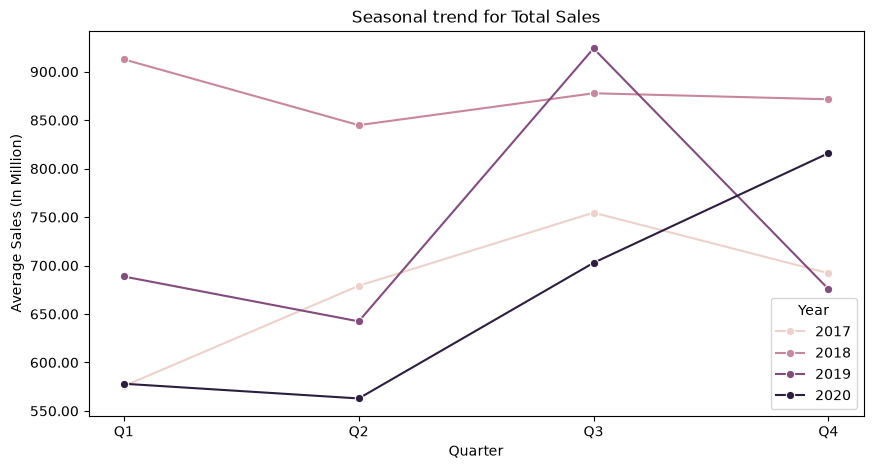

In [ ]:
# Сезонные тренды в продажах
df1 = df.copy()
df1['Month'] = df1['Date'].dt.month
df1['Year'] = df1['Date'].dt.year

df1['Quarter'] = pd.cut(df1['Month'], bins=[0, 3, 6, 9, 12], labels=['Q1', 'Q2', 'Q3', 'Q4'], right=True)

Quarterly_sales = df1.groupby(['Year', 'Quarter'], observed=False)['Sales'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=Quarterly_sales, x='Quarter', y='Sales', hue='Year', marker='o')

plt.xlabel('Quarter')
plt.ylabel('Average Sales (In Million)')
plt.title(f'Seasonal trend for Total Sales')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{x/1000000:,.2f}'))
plt.show()

Анализ тенденций продаж по кварталам показал, что третий квартал (Q3) стабильно фиксировал наибольший объём продаж в большинстве лет. Единственным исключением стал 2020 год, когда наивысшие продажи пришлись на четвёртый квартал (Q4).

Второй квартал (Q2) в целом показывал самые низкие продажи, за исключением 2017 года, когда слабейшим оказался первый квартал (Q1). Эти сезонные закономерности могут быть связаны с климатическим спросом, циклами заболеваемости или стратегическими кампаниями по продажам.

In [ ]:
# Сезонные тренды в продажах по продукту
def seasona_trend(product):

    product_data = df1[df1['Product Name']== product].copy()

    Quarterly_sales = product_data.groupby(['Year', 'Quarter'], observed=False)['Sales'].sum().reset_index()

    plt.figure(figsize=(10, 5))
    sns.lineplot(data=Quarterly_sales, x='Quarter', y='Sales', hue='Year', marker='o')

    plt.xlabel('Quarter')
    plt.ylabel('Sales(In Million)')
    plt.title(f'Seasonal trend for {product}')
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{x/1000000:,.2f}'))
    plt.show()


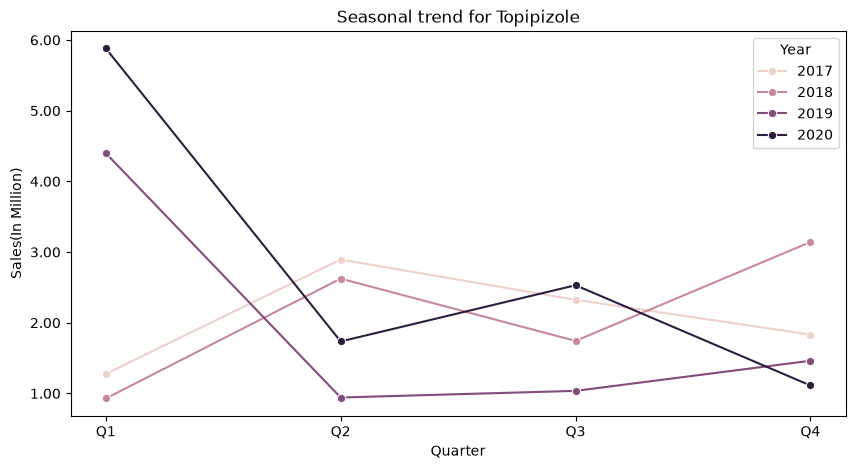

In [31]:
product = input('Enter Product Name:')
seasona_trend(product)

Для анализа сезонных тенденций по отдельным продуктам использовалась пользовательская функция. Например, у Choriotrisin стабильно наблюдался пик продаж в третьем квартале с резким подъёмом, что указывает на сезонную вспышку спроса — возможно, связанную с проблемами со здоровьем, более распространёнными в это время года. Этот метод можно применять и к другим продуктам, чтобы выявлять сезонные зависимости и точнее прогнозировать спрос.

In [ ]:
# Ключевое изменение продукта или продаж в конкретном году
def yearly_trend(product_year):

    product_data = df[df['Product Name']== product].copy()

    Yearly_sales = product_data.groupby(['Product Name', 'Year'], observed=False)['Sales'].sum().reset_index()
    
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=Yearly_sales, x='Year', y='Sales', marker='o', color='Blue')

    plt.xlabel('Year')
    plt.ylabel('Sales(In Million)')
    plt.title(f'Yearly trend for {product_year}')
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{x/1000000:,.2f}'))
    plt.show()



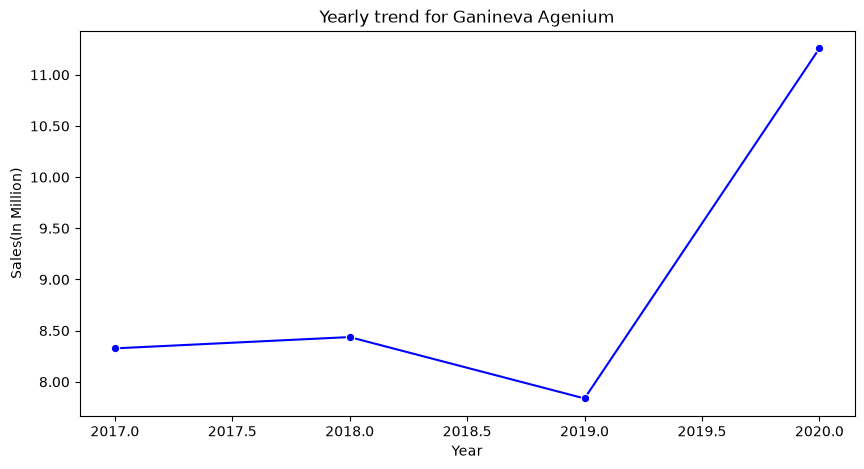

In [15]:
product_year = input('Enter Product Name:')
yearly_trend(product_year)

Аналогичная функция использовалась для анализа годовых тенденций по отдельным продуктам. Например, у Choriotrisin наивысшие продажи пришлись на 2018 год, что указывает на возможный всплеск интереса к продукту, успех кампании или рост рыночного спроса в тот год. Такой подход помогает выявлять значительные изменения в показателях продуктов год к году и может служить основой для стратегического планирования.

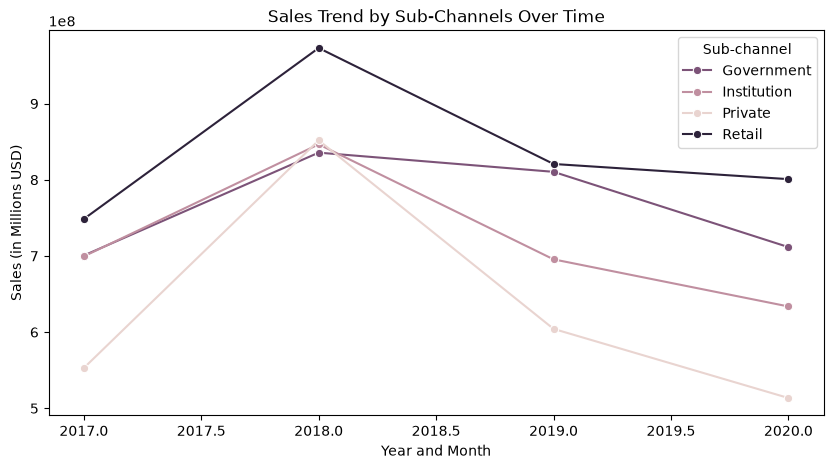

In [ ]:
# Тренды продаж по субканалам 
subchannel_year_sale = df.groupby(['Sub-channel','Year'])['Sales'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=subchannel_year_sale, x='Year', y='Sales', hue='Sub-channel', marker='o', palette=['#7C5378', '#C08FA0', '#E9D4D0', '#2D223A'])

plt.xlabel('Year and Month')
plt.ylabel('Sales (in Millions USD)')
plt.title('Sales Trend by Sub-Channels Over Time')
plt.gca().yaxis.set_major_formatter(FuncFormatter(millions)) 
plt.show()

Сравнительный анализ всех комбинаций каналов и субканалов за разные годы показал схожую картину роста по всем направлениям. Все категории достигли наилучших результатов в 2018 году, что указывает на пиковый год для бизнеса независимо от способа сбыта. Эта единообразная тенденция говорит о том, что канал и подканал существенно не влияют на объём продаж.

5. Анализ категорий продукта

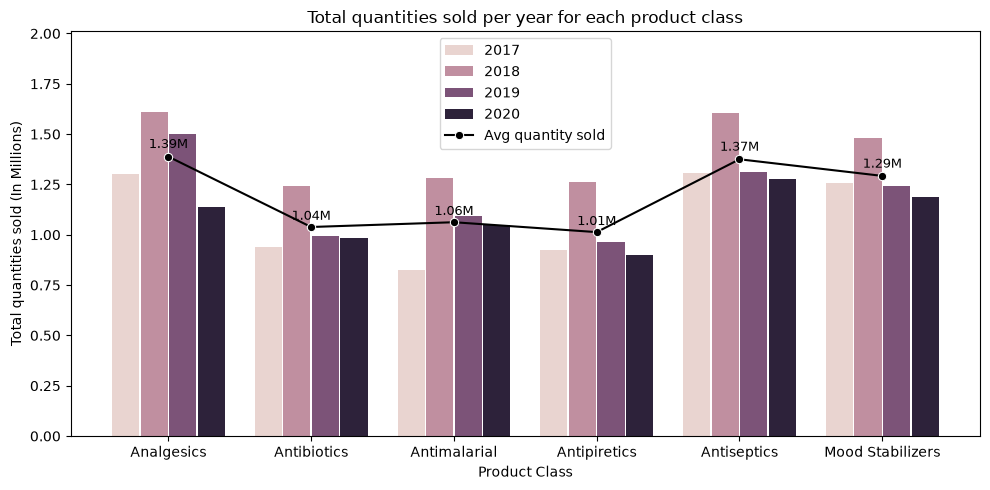

In [ ]:
# Наиболее популярные категории продукта
product_class = df.groupby(['Product Class', 'Year'])['Quantity'].sum().reset_index()

product_class_avg = product_class.groupby('Product Class')['Quantity'].mean().reset_index()

plt.figure(figsize=(10,5))
mc = sns.barplot(data=product_class, x='Product Class', y='Quantity', hue='Year', gap=0.05)
sns.lineplot(data=product_class_avg, x='Product Class', y='Quantity', color='black', marker='o', label='Avg quantity sold')

for i, row in product_class_avg.iterrows():
    mc.text(i, row['Quantity'] + 0.02 * row['Quantity'], f'{row['Quantity']/1000000:,.2f}M', 
            ha='center', va='bottom', fontsize=9, color='black')
    
plt.title('Total quantities sold per year for each product class')
plt.ylim(0, product_class['Quantity'].max() + 400000 )
plt.xlabel('Product Class')
plt.ylabel('Total quantities sold (In Millions)')
plt.gca().yaxis.set_major_formatter(FuncFormatter (lambda x, pos: f'{x/1000000:,.2f}'))
plt.tight_layout() 
plt.show()

Анальгетики оказались самым популярным классом продуктов в среднем, за ними следуют антисептики и нормотимики. Однако были отмечены годовые колебания — например, в 2020 году наибольший объём продаж зафиксирован у антисептиков. На противоположном конце спектра антипиретики стабильно показывали наименьший суммарный объём продаж.

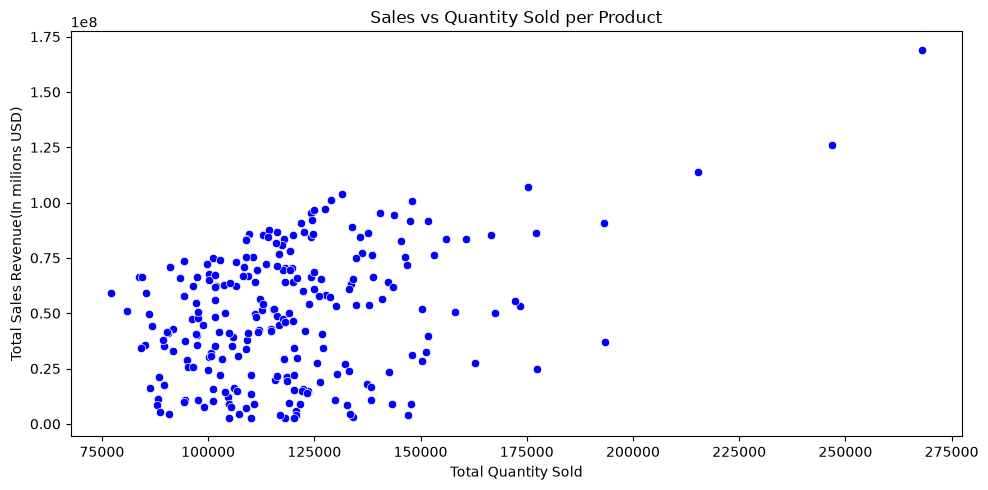

In [ ]:
# Продукты с высоким числом продаж но маленькой выручкой
product_perf = df.groupby('Product Name')[['Quantity', 'Sales']].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=product_perf, x='Quantity', y='Sales', color='Blue')

plt.title('Sales vs Quantity Sold per Product')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Total Sales Revenue(In milions USD)')
plt.tight_layout()
plt.show()

Диаграмма рассеяния, сопоставляющая суммарное количество проданных единиц и общую выручку от продаж, выявила прямую пропорциональную зависимость. Ни у одного продукта не наблюдалось ситуации «высокая выручка при низком количестве» или наоборот. Это говорит о том, что выручка в значительной степени определяется количеством проданного товара.

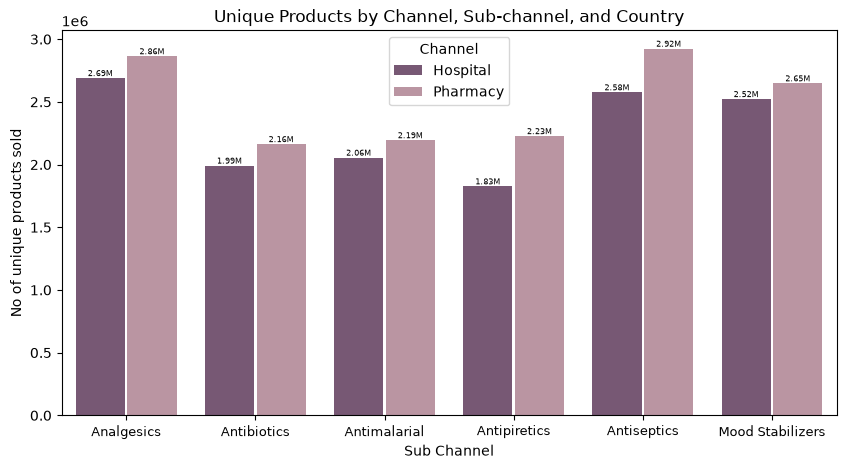

In [ ]:
# Количество продукта, проданное в аптечном и госпитальном каналах
product_class_channel = df.groupby(['Channel','Product Class'])['Quantity'].sum().reset_index()

plt.figure(figsize=(10,5))
gc = sns.barplot(data=product_class_channel, x='Product Class', y='Quantity', hue='Channel', gap=0.05, palette=['#7C5378','#C08FA0'])

for i in gc.patches:
    if i.get_height()>0:
        gc.annotate(f'{i.get_height() / 1000000:,.2f}M', 
                   (i.get_x() + i.get_width()/2, i.get_height()), ha='center', va='bottom', fontsize=6)


plt.title('Unique Products by Channel, Sub-channel, and Country')
plt.xlabel('Sub Channel')
plt.xticks(rotation=0, fontsize=9)
plt.ylabel('No of unique products sold')
plt.show()

В целом аптеки закупают больше продукции, чем больницы. Наиболее выраженный разрыв наблюдался по антипиретикам, тогда как нормотимики продавались почти в равных объёмах и больницам, и аптекам, что говорит об их универсальном спросе.

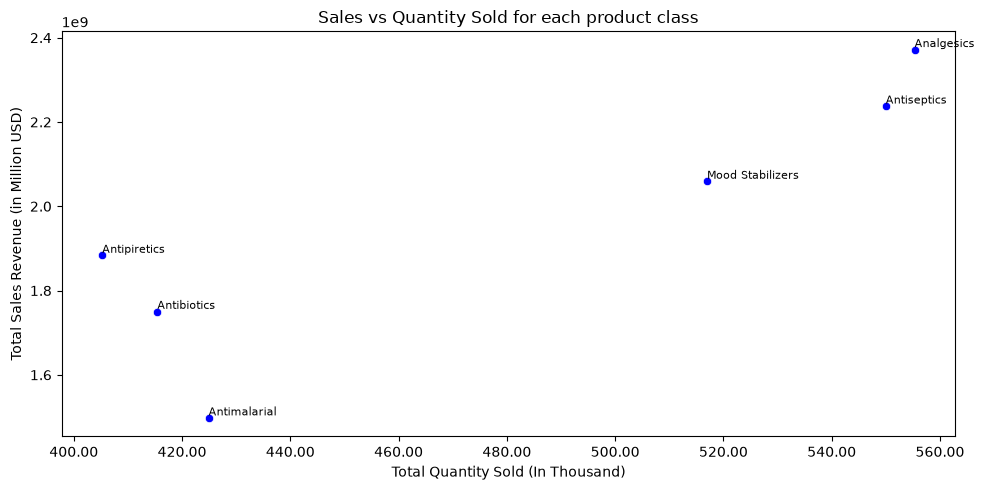

In [ ]:
# Классы продуктов с высокой выручкой при малом объёме заказов — то есть премиальные продукты
product_perf_class = df.groupby('Product Class')[['Quantity', 'Sales']].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=product_perf_class, x='Quantity', y='Sales', color='Blue')

for i in range(product_perf_class.shape[0]):
    plt.text(
        product_perf_class['Quantity'][i],
        product_perf_class['Sales'][i],
        product_perf_class['Product Class'][i],
        fontsize=8,
        ha='left',
        va='bottom'
    )

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/10000:.2f}'))
plt.title('Sales vs Quantity Sold for each product class')
plt.xlabel('Total Quantity Sold (In Thousand)')
plt.ylabel('Total Sales Revenue (in Million USD)')
plt.tight_layout()
plt.show()

Диаграмма рассеяния, сопоставляющая количество проданных единиц по классам продуктов и общую выручку, не выявила премиальных классов — то есть ни один класс не показал высокую выручку при малом объёме продаж. Такие классы, как антипиретики, антибиотики и противомалярийные, имели одновременно и низкое количество проданных единиц, и низкую выручку; тогда как нормотимики, антисептики и анальгетики обеспечивали высокую выручку за счёт больших объёмов продаж.

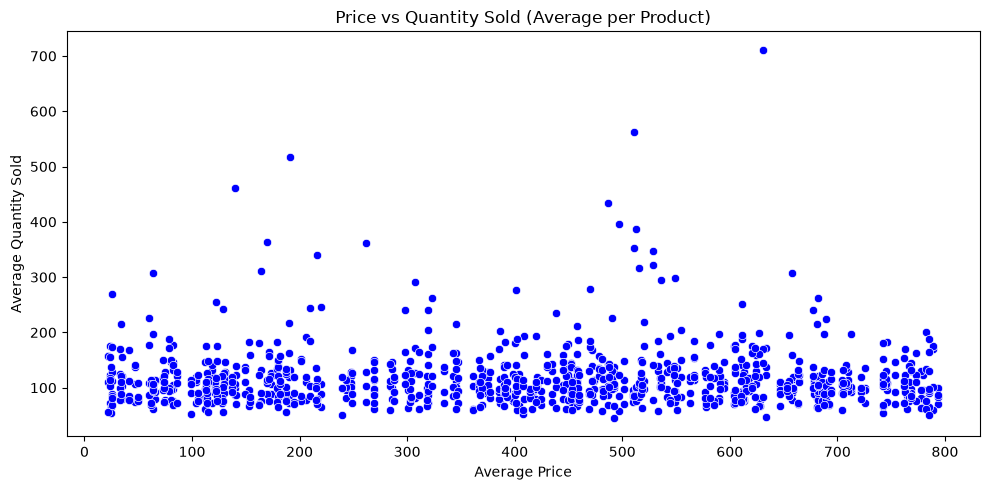

In [ ]:
# Корреляции изменения цены и количества проданного товара
product_year = df.groupby(['Product Name', 'Year'])[['Price', 'Quantity']].mean().reset_index()
product_year['Price Change'] = product_year.groupby('Product Name')['Price'].pct_change()
price_change_product = product_year[(product_year['Price Change'].notna()) & (product_year['Price Change'] != 0)]

plt.figure(figsize=(10, 5))
sns.scatterplot(data=product_year, x='Price', y='Quantity', color='Blue')
plt.title('Price vs Quantity Sold (Average per Product)')
plt.xlabel('Average Price')
plt.ylabel('Average Quantity Sold')
plt.tight_layout()
plt.show()

In [35]:
product_year['Price'].corr(product_year['Quantity'])

np.float64(-0.01230734304387025)

Анализ подтвердил, что цены на продукты оставались неизменными в течение четырёхлетнего периода. При сопоставлении фиксированных цен с объёмами продаж на диаграмме рассеяния значимой корреляции между ценой и количеством проданных единиц не наблюдалось. Это говорит о том, что продажи определяются не ценой, а другими факторами — например, спросом или сезонностью.

6. Эффективность отдела продаж 

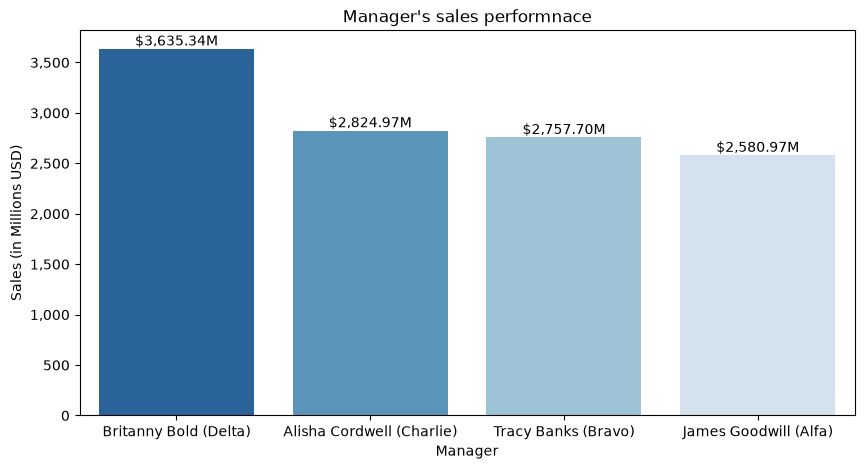

In [ ]:
# Менеджеры с наиболее результативными командами продаж
manager_sales = df.groupby(['Manager', 'Sales Team'])['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False)

manager_sales['Label'] = manager_sales['Manager'] + ' (' + manager_sales['Sales Team'] + ')'

plt.figure(figsize = (10,5))
ax = sns.barplot(data = manager_sales, x='Label', y='Sales', palette='Blues_r', hue='Label')

for i in ax.patches:
    ax.annotate(f'${i.get_height() / 1_000_000:,.2f}M',
               (i.get_x() + i.get_width() / 2, i.get_height()), ha='center', va='bottom')
    
def millions(x, pos):
    return f'{int(x/1_000_000):,}'
ax.yaxis.set_major_formatter(FuncFormatter(millions))
                
plt.xlabel('Manager')
plt.ylabel('Sales (in Millions USD)')
plt.title("Manager's sales performnace")
plt.show()

Среди всех команд команда Delta под руководством Britanny Bold стабильно генерировала наибольший суммарный объём продаж, что делает её самой результативной командой продаж за весь анализируемый период.

In [ ]:
# Количество торговых представителей у каждого менеджера
manager_Rep = df.groupby(['Manager'])['Name of Sales Rep'].nunique().reset_index().sort_values(
    by='Name of Sales Rep', ascending=False).rename(
    columns={'Name of Sales Rep': 'No of Sales Rep'})
manager_Rep 

,Manager,No of Sales Rep
1,Britanny Bold,4
0,Alisha Cordwell,3
2,James Goodwill,3
3,Tracy Banks,3


Britanny Bold руководила самой большой командой — 4 торговых представителя, тогда как у всех остальных менеджеров в подчинении было по 3 представителя.

In [65]:
# Торговый представитель с наибольшей выручкой от продаж
revenue_rep = df.groupby('Name of Sales Rep')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False)
highest_revenue_rep = revenue_rep.iloc[0]['Name of Sales Rep']
highest_revenue_rep_sales = revenue_rep.iloc[0]['Sales']
print(f'Торговый представитель с наибольшей выручкой от продаж:  {highest_revenue_rep} (${highest_revenue_rep_sales:,.2f})')

Торговый представитель с наибольшей выручкой от продаж:  Jimmy Grey ($985,969,993.94)


Jimmy Grey был признан самым результативным торговым представителем, так как обеспечил наибольшую суммарную выручку от продаж среди всех сотрудников

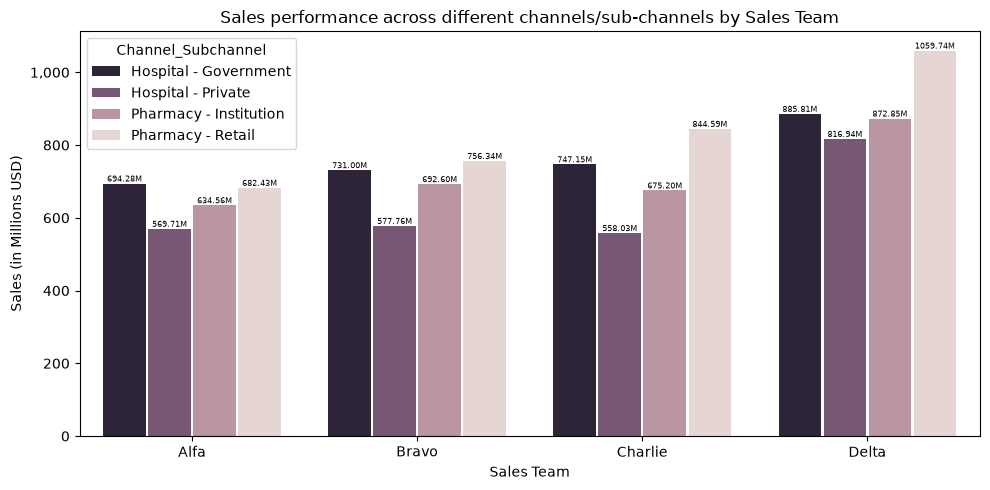

In [ ]:
# Различия в показателях продаж по разным каналам или подканалам, которыми управляет одна и та же команда продаж
df1['Channel_Subchannel'] = df1['Channel'] + ' - ' + df1['Sub-channel']

sales_team_channel = df1.groupby(['Sales Team', 'Channel_Subchannel'])['Sales'].sum().reset_index()

plt.figure(figsize=(10, 5))
gc = sns.barplot(data=sales_team_channel, x='Sales Team', y='Sales', hue='Channel_Subchannel', gap=0.05, palette=['#2D223A','#7C5378', '#C08FA0', '#E9D4D0'])

for bar in gc.patches:
    if bar.get_height() >0:
        gc.annotate(f'{bar.get_height() / 1_000_000:.2f}M', 
                    (bar.get_x() + bar.get_width()/2, bar.get_height()), 
                    ha='center', va='bottom', fontsize=6)

plt.title('Sales performance across different channels/sub-channels by Sales Team')
plt.xlabel('Sales Team')
plt.xticks(rotation=0)
plt.ylabel('Sales (in Millions USD)')
plt.gca().yaxis.set_major_formatter(FuncFormatter(millions))
plt.tight_layout()
plt.show()

Тенденции продаж по различным каналам и подканалам были единообразными для всех команд. Во всех случаях наибольшие продажи зафиксированы в связке «Pharmacy — Retail», а наименьшие — в частных больницах. Все команды работали со всеми комбинациями каналов и подканалов, что указывает на равномерное распределение ответственности.

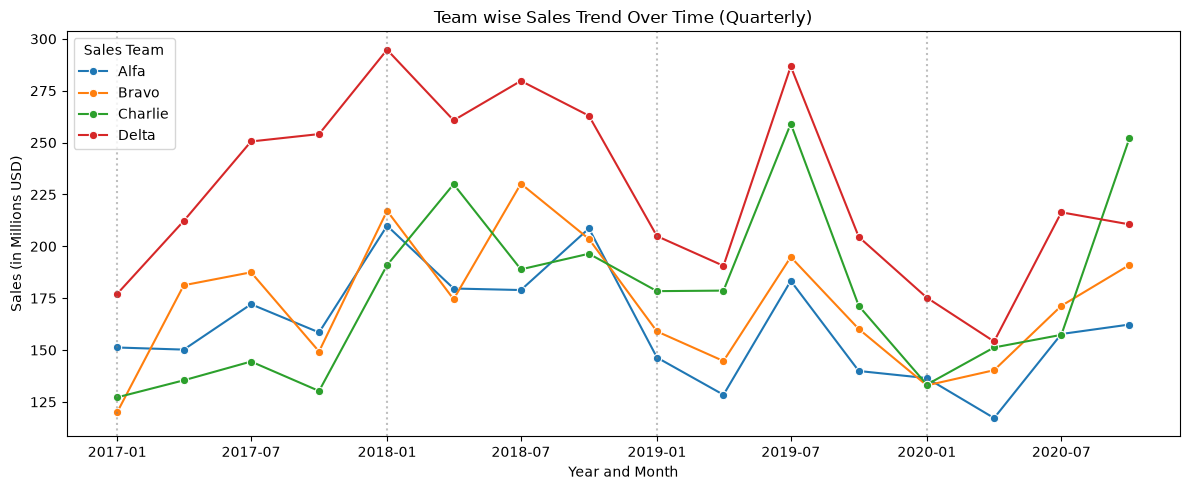

In [ ]:
# Продажи по командам в разрезе лет
df1['Year-Quarter'] = df1['Date'].dt.to_period('Q')
df1['Year-Quarter-Date'] = df1['Year-Quarter'].dt.start_time

df_grouped = df1.groupby(['Year-Quarter-Date', 'Sales Team'])['Sales'].sum().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(data=df_grouped, x='Year-Quarter-Date', y='Sales', marker='o', hue='Sales Team', palette='tab10')

for year in df_grouped['Year-Quarter-Date'].dt.year.unique():
    plt.axvline(pd.to_datetime(f'{year}-01-01'), color='gray', linestyle=':', alpha=0.5)

plt.xlabel('Year and Month')
plt.ylabel('Sales (in Millions USD)')
plt.title('Team wise Sales Trend Over Time (Quarterly)')

plt.gca().yaxis.set_major_formatter(FuncFormatter(millions))

plt.tight_layout()
plt.show()

Команда Delta опережала все остальные с 2017 по 2019 год, причём её продажи стабильно превышали показатели других команд. Однако в 2020 году её результаты значительно снизились.

Остальные три команды демонстрировали схожий уровень показателей: команда Charlie заняла второе место в 2019 году и зафиксировала наибольшие квартальные продажи в Q4 2020, превзойдя даже Delta.

In [ ]:
# Сводка по городам, клиентам, продуктам и классам продуктов, с которыми работает каждая команда продаж
summary = df.groupby('Sales Team').agg({
    'City': 'nunique',
    'Customer Name': 'nunique',
    'Product Name': 'nunique',
    'Product Class': 'nunique'}).reset_index()
summary

,Sales Team,City,Customer Name,Product Name,Product Class
0,Alfa,749,751,240,6
1,Bravo,749,751,240,6
2,Charlie,749,751,240,6
3,Delta,749,751,240,6


Все команды работали во всех городах, взаимодействовали со всеми типами клиентов и отвечали за продажу всех продуктов и классов продуктов, что указывает на целостную, несегментированную структуру команд.

 7. Аналитика по клиентам

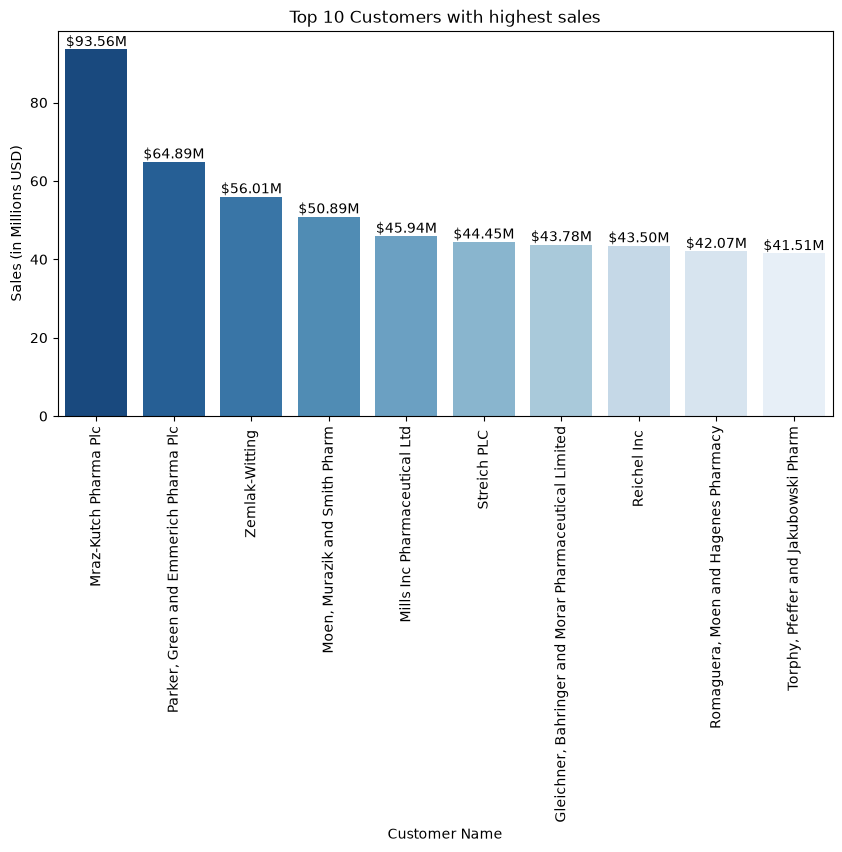

In [ ]:
# Топ-10 клиентов по объёму продаж
revenue_cities = df.groupby('Customer Name')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False).head(10)

plt.figure(figsize = (10,5))
ax = sns.barplot(data = revenue_cities, x='Customer Name', y='Sales', palette='Blues_r', hue='Customer Name')

for i in ax.patches:
    ax.annotate(f'${i.get_height() / 1_000_000:,.2f}M',
               (i.get_x() + i.get_width() / 2, i.get_height()), ha='center', va='bottom')
    
def millions(x, pos):
    return f'{int(x/1_000_000):,}'
ax.yaxis.set_major_formatter(FuncFormatter(millions))
                
plt.xlabel('Customer Name')
plt.ylabel('Sales (in Millions USD)')
plt.xticks(rotation=90)
plt.title('Top 10 Customers with highest sales')
plt.show()

Mraz-Kutch Pharma Plc стал крупнейшим клиентом по общему объёму продаж — выручка приблизилась к $95 млн. Столбчатая диаграмма дополнительно показывает остальных клиентов, вошедших в топ-10 по выручке.

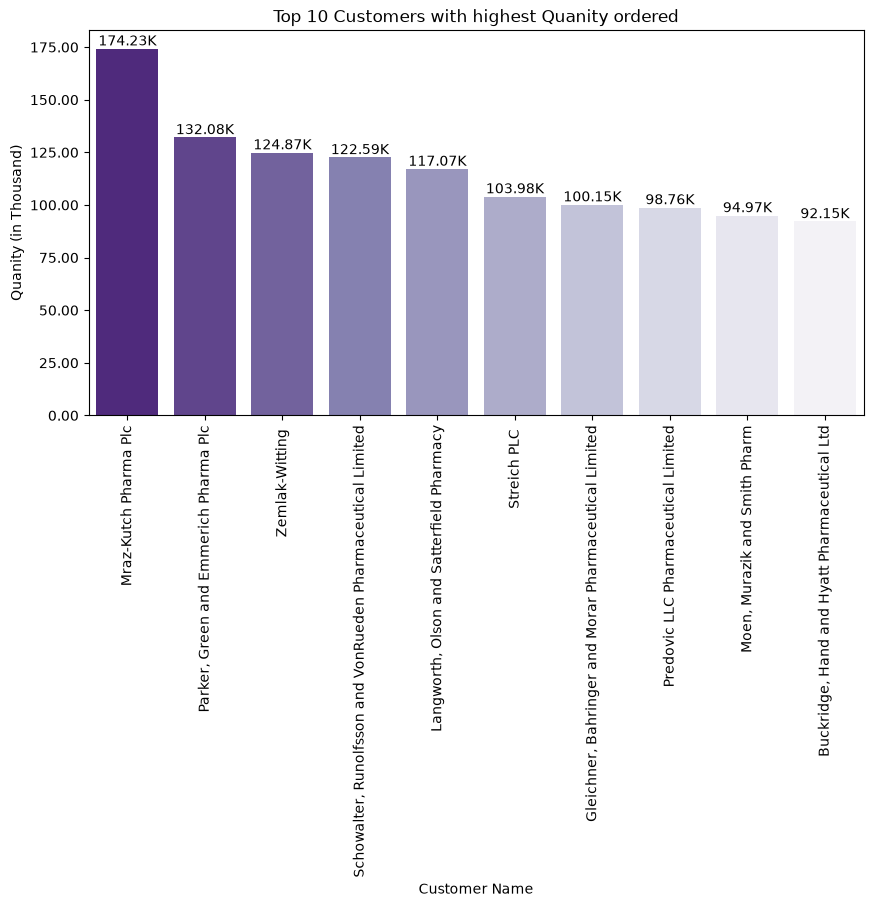

In [ ]:
# Топ-10 клиентов по наибольшему количеству заказов
revenue_cities = df.groupby('Customer Name')['Quantity'].sum().reset_index().sort_values(by='Quantity', ascending=False).head(10)

plt.figure(figsize = (10,5))
ax = sns.barplot(data = revenue_cities, x='Customer Name', y='Quantity', palette='Purples_r', hue='Customer Name')

for i in ax.patches:
    ax.annotate(f'{i.get_height() / 1000:,.2f}K',
               (i.get_x() + i.get_width() / 2, i.get_height()), ha='center', va='bottom')
    
def millions(x, pos):
    return f'{int(x/1_000_000):,}'
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1000:,.2f}'))
                
plt.xlabel('Customer Name')
plt.ylabel('Quanity (in Thousand)')
plt.xticks(rotation=90)
plt.title('Top 10 Customers with highest Quanity ordered')
plt.show()

Mraz-Kutch Pharma Plc также заняла первое место по общему количеству заказанных единиц, закупив почти 176 000 единиц. Остальные крупнейшие клиенты показаны на прилагаемой столбчатой диаграмме.

In [66]:
# Среднее количество уникальных продуктов, приобретаемых каждым клиентом
customer_product = df.groupby('Customer Name').agg({
    'Product Name': 'nunique'}).reset_index()
avg_unique_products_per_customer = customer_product['Product Name'].mean()
print(f"Среднее количество уникальных продуктов, приобретаемых каждым клиентом: {avg_unique_products_per_customer:.2f}")

Среднее количество уникальных продуктов, приобретаемых каждым клиентом: 177.30


В среднем каждый клиент приобретал около 177 различных продуктов из 240 доступных, что свидетельствует о широких и разнообразных продуктовых предпочтениях.

In [ ]:
# Какие дистрибьюторы закупали наиболее широкий ассортимент продуктов или классов продуктов
customer_product.sort_values(by='Product Name', ascending=False).head(10).rename(columns={'Product Name': 'Number of Products'})

,Customer Name,Number of Products
710,Welch-Orn Pharmacy,208
186,Fritsch LLC Pharmaceutical Ltd,206
492,Parisian Ltd Pharma Plc,205
187,"Fritsch, Hodkiewicz and Sipes Pharma Plc",205
415,Mann-Waelchi Pharma Plc,204
87,Buckridge-Davis Pharmaceutical Limited,204
499,Paucek PLC,204
541,"Reinger, Kihn and Goyette Pharma Plc",203
340,Konopelski-Blick Pharmaceutical Limited,203
473,"Nolan, DuBuque and Schultz",203


Welch-Orn Pharmacy выделилась как дистрибьютор с самым разнообразным ассортиментом закупок: более 208 уникальных продуктов из 240 — что подчёркивает широкий охват портфеля.

8. Заключение
Комплексный анализ продаж и продуктов на уровне транзакций за четыре года позволил получить ряд стратегических выводов, которые могут существенно поддержать принятие решений на основе данных и оптимизацию эффективности по всей организации.

- Ключевые выводы
Устойчивый рост с пиком в 2018 году. Продажи и объёмы по всем каналам и командам достигли наивысших показателей в 2018 году, что указывает на благоприятные рыночные условия и, возможно, на оптимизированные процессы продаж в этот период.

- Сезонные и месячные тенденции. 
Продажи стабильно достигали пика в Q3, особенно в августе и ноябре, за исключением 2020 года, когда максимум пришёлся на Q4. Эти сезонные закономерности отражают особенности рыночного поведения, включая сезонность заболеваний и циклы закупок.

- Показатели продуктов
1. Анальгетики, антисептики и нормотимики оказались самыми популярными классами продуктов.
2. Между количеством проданных единиц и общим объёмом продаж наблюдалась прямая корреляция, что говорит об отсутствии «премиальных» продуктов с малым объёмом и высокой маржой.
3. Изменения цен не оказали заметного влияния на спрос — вероятно, из-за стабильности цен в течение периода.

- Эффективность команд продаж
1. Команда Delta под руководством Britanny Bold стала лучшей по итогам периода, но показала заметное снижение в 2020 году.
2. Jimmy Grey лидировал среди всех торговых представителей по выручке.
3. Тенденции продаж были единообразными по всем каналам для всех команд, а «Аптека — Розница» вышла на первое место как основной источник выручки.

- Поведение клиентов
1. Mraz-Kutch Pharma Plc выделилась как крупнейший клиент и по выручке, и по объёму заказов.
2. В среднем клиенты приобретали около 73% доступных продуктов; у Welch-Orn Pharmacy зафиксирован самый разнообразный ассортимент закупок.

- Бизнес-выводы
1. Распределение ресурсов. Знание того, какие кварталы и месяцы показывают лучшие результаты, позволяет улучшить управление запасами и планирование ресурсов в пиковые сезоны.
2. Сегментация клиентов. Выявление ключевых клиентов и их покупательского поведения открывает возможности для адресного управления отношениями и персонализированных стратегий обслуживания.
3. Управление продуктовым портфелем. Поскольку основная часть выручки формируется высокообъёмными продуктами, усилия стоит направить на поддержание спроса и одновременно изучить потенциал введения высокомаржинальных премиальных продуктов.
4. Оптимизация работы отдела продаж. Понимание сильных и слабых сторон каждой команды и каждого представителя позволяет выстроить целевое обучение и управление эффективностью.

-Рекомендуемые дальнейшие шаги
1. Углублённый анализ слабых периодов и команд. Разобраться в причинах падения показателей команды Delta в 2020 году и изучить внешние и внутренние факторы, которые могли на это повлиять.
2. Стратегия продуктовых инноваций. Изучить возможности разработки премиальных продуктовых линеек с более высокой маржой на единицу.
3. Программы лояльности клиентов. Разработать стратегии удержания ключевых клиентов и стимулировать клиентов из «длинного хвоста» к расширению ассортимента заказов.
4. Продвинутые модели прогнозирования. Внедрить предиктивную аналитику на основе моделей временных рядов, чтобы точнее предугадывать спады и всплески продаж с учётом сезонных и макроэкономических индикаторов.
5. Расширение стратегий по подканалам. Хотя подканалы демонстрировали схожие тенденции, адресные стратегии могут раскрыть неиспользованный потенциал в менее результативных направлениях, таких как частные больницы.